# Telco Customer Churn: Exploratory Data Analysis (Task 1)
**CM2604 Machine Learning, Part 01**

Goal: understand the data before modelling. We check data quality, the target (`Churn`), each feature's distribution and its relationship with churn.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
os.makedirs("../figures", exist_ok=True)   # figures are saved for use in the report

DATA_PATH = "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Data overview and quality checks

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
# Missing values (as NaN), duplicate rows and duplicate customer IDs
print("NaN values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customerIDs:", df["customerID"].duplicated().sum())

NaN values: 0
Duplicate rows: 0
Duplicate customerIDs: 0


**Hidden problem: `TotalCharges`.** It is stored as text (`object`), even though it should be numeric. Some rows probably contain blank strings, which pandas does not count as NaN.

In [4]:
# Convert to numeric; blanks become NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("TotalCharges missing after conversion:", df["TotalCharges"].isna().sum())
df.loc[df["TotalCharges"].isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

TotalCharges missing after conversion: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


All 11 rows have `tenure = 0`: they are brand-new customers who have not been billed yet, so a missing `TotalCharges` is logical. They are only 0.16% of the data. In preprocessing we will set these to 0 (they have paid nothing yet) or drop them, and justify the choice there.

In [5]:
# Binary version of the target, used later for correlations and churn rates
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns
            if df[c].dtype == "object" and c not in ["customerID", "Churn"]] + ["SeniorCitizen"]
print("Numeric:", num_cols)
print("Categorical:", cat_cols)
df[num_cols].describe().round(2)

Numeric: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: ['SeniorCitizen']


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.00
mean,32.37,64.76,2283.30
std,24.56,30.09,2266.77
min,0.00,18.25,18.80
25%,9.00,35.50,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.85,3794.74
max,72.00,118.75,8684.80


## 2. Target variable: class balance

       count  percent
Churn                
No      5174     73.5
Yes     1869     26.5


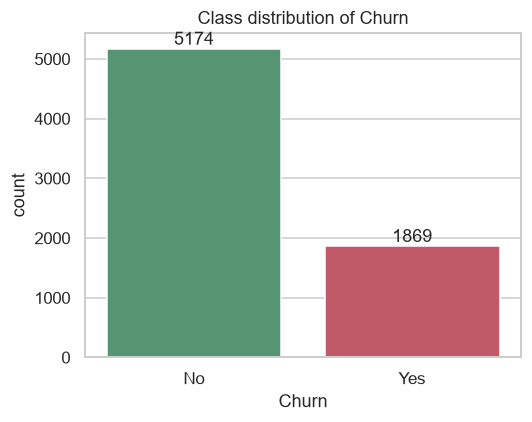

In [6]:
counts = df["Churn"].value_counts()
pct = df["Churn"].value_counts(normalize=True).mul(100).round(1)
print(pd.DataFrame({"count": counts, "percent": pct}))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="Churn", hue="Churn", palette=["#4C9F70", "#D1495B"], legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Class distribution of Churn")
plt.tight_layout(); plt.savefig("../figures/01_class_distribution.png"); plt.show()

The classes are **imbalanced**: about 73.5% stay and 26.5% churn. A model that always predicts "No" would score ~73.5% accuracy while catching no churners, so accuracy alone is a poor metric. We will use precision, recall, F1 and ROC-AUC, and consider stratified splits and class weighting.

## 3. Numerical features

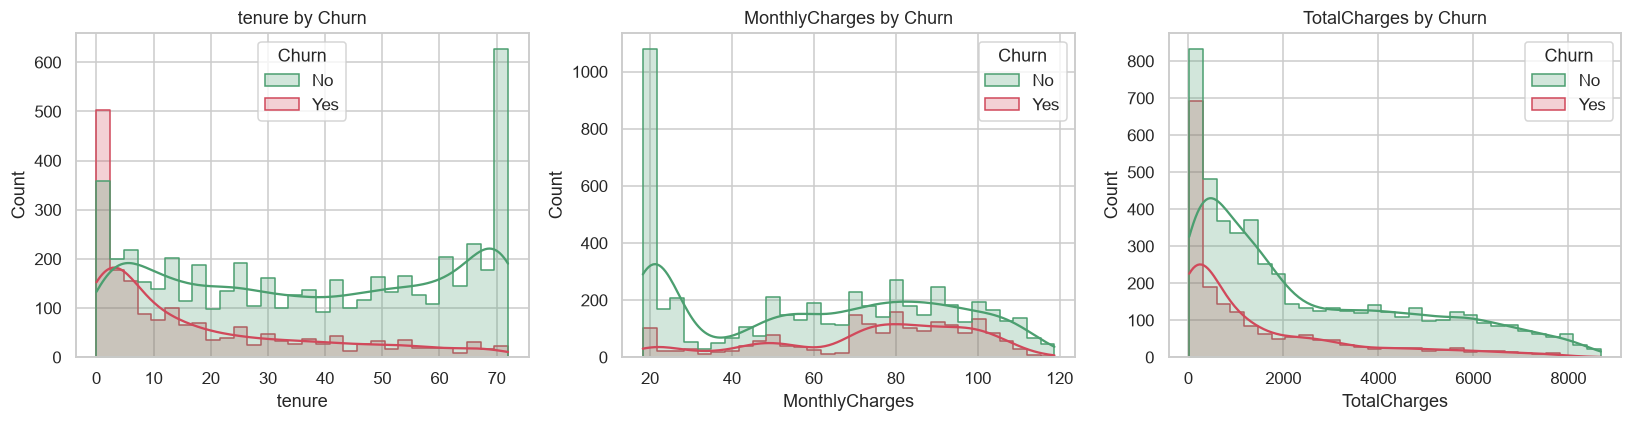

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue="Churn", kde=True, bins=30, element="step",
                 palette=["#4C9F70", "#D1495B"], ax=ax)
    ax.set_title(f"{col} by Churn")
plt.tight_layout(); plt.savefig("../figures/02_numeric_distributions.png"); plt.show()

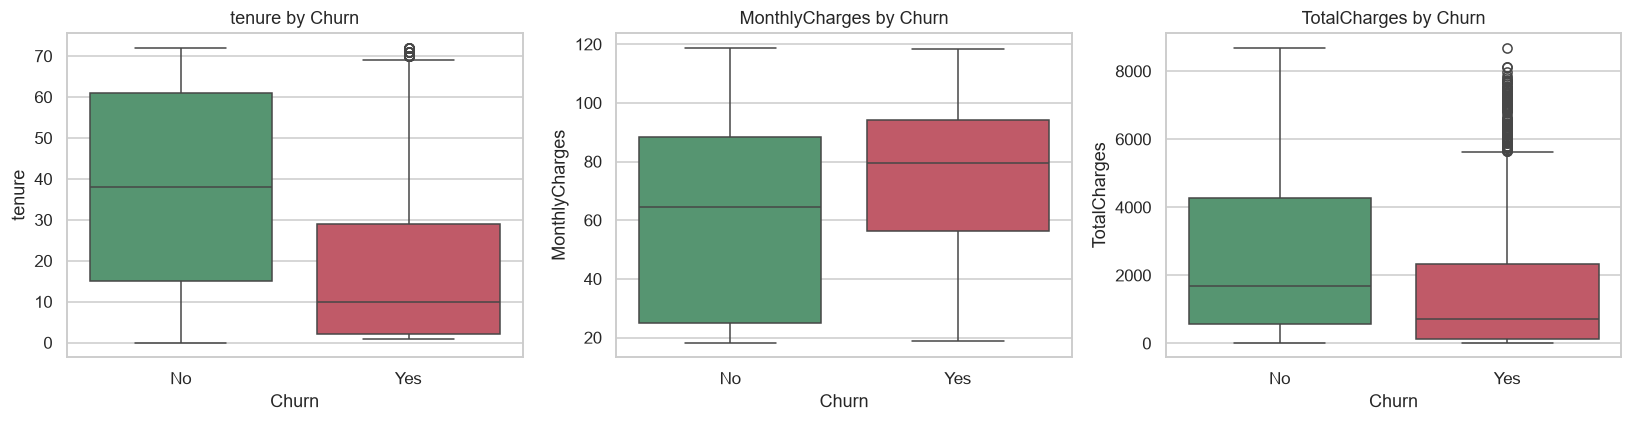

       tenure  MonthlyCharges  TotalCharges
Churn                                      
No       38.0            64.4        1683.6
Yes      10.0            79.6         703.6


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="Churn", y=col, hue="Churn", palette=["#4C9F70", "#D1495B"], legend=False, ax=ax)
    ax.set_title(f"{col} by Churn")
plt.tight_layout(); plt.savefig("../figures/03_numeric_boxplots.png"); plt.show()

print(df.groupby("Churn")[num_cols].median().round(1))

- Churners have a much **lower tenure** (median 10 months vs 38 for stayers).
- Churners pay **higher monthly charges** (median about 79.7 vs 64.4).
- `TotalCharges` is lower for churners, but mostly because they have been customers for less time (it is roughly tenure × monthly charge).
- The boxplots show no serious outliers in these columns, so no outlier removal is needed.

TenureBand
0-12     47.4
13-24    28.7
25-48    20.4
49-72     9.5
Name: ChurnFlag, dtype: float64


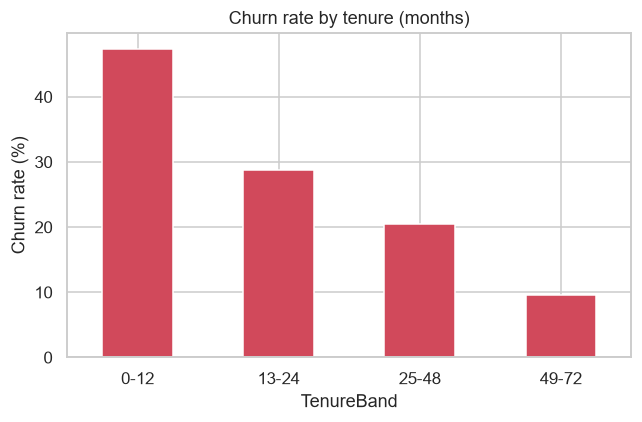

In [9]:
# Churn rate by tenure band
df["TenureBand"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                          labels=["0-12", "13-24", "25-48", "49-72"])
rate = df.groupby("TenureBand", observed=True)["ChurnFlag"].mean().mul(100).round(1)
print(rate)

ax = rate.plot(kind="bar", color="#D1495B", figsize=(6, 4), rot=0)
ax.set_ylabel("Churn rate (%)"); ax.set_title("Churn rate by tenure (months)")
plt.tight_layout(); plt.savefig("../figures/04_churn_by_tenure.png"); plt.show()

Churn falls steadily with tenure: about 47% in the first year but only about 9.5% after four years. Customers are most at risk early on.

## 4. Categorical features

In [ ]:
# Churn rate (%) for every category of every categorical feature
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
for ax, col in zip(axes.flat, cat_cols):
    r = df.groupby(col)["ChurnFlag"].mean().mul(100).sort_values()
    sns.barplot(x=r.values, y=r.index.astype(str), color="#D1495B", ax=ax)
    ax.axvline(df["ChurnFlag"].mean() * 100, color="black", ls="--", lw=1)
    ax.set_title(col); ax.set_xlabel("Churn rate (%)"); ax.set_ylabel("")
for ax in axes.flat[len(cat_cols):]:
    ax.set_visible(False)
plt.suptitle("Churn rate by category (dashed line = overall churn rate 26.5%)", y=1.0)
plt.tight_layout(); plt.savefig("../figures/05_categorical_churn_rates.png"); plt.show()

In [ ]:
# Detailed views of the strongest drivers
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    sns.countplot(data=df, x=col, hue="Churn", palette=["#4C9F70", "#D1495B"], ax=ax)
    ax.set_title(f"{col} vs Churn")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.savefig("../figures/06_key_categorical_counts.png"); plt.show()

for col in ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "SeniorCitizen"]:
    print(df.groupby(col)["ChurnFlag"].mean().mul(100).round(1).to_dict())

**What stands out**
- **Contract:** month-to-month customers churn at 42.7%, one-year at 11.3%, two-year at only 2.8%. This is the strongest categorical driver.
- **Internet service:** fibre optic customers churn at 41.9% versus 19.0% for DSL and 7.4% for no internet.
- **Payment method:** electronic check users churn at 45.3%, far above the automatic payment methods (about 15 to 17%).
- **Support and security add-ons:** customers without Tech Support (41.6%) or Online Security (41.8%) churn far more than those with them (about 15%).
- **Demographics:** senior citizens churn more (41.7% vs 23.6%), and customers with a partner or dependents churn less. **Gender and PhoneService have almost no effect** (26.9% vs 26.2% for gender).
- Several columns have a "No internet service" or "No phone service" category. These are redundant with `InternetService` and `PhoneService`, which matters for encoding.

## 5. Correlations

In [ ]:
corr = df[num_cols + ["SeniorCitizen", "ChurnFlag"]].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (numeric features)")
plt.tight_layout(); plt.savefig("../figures/07_correlation_heatmap.png"); plt.show()

print(corr["ChurnFlag"].drop("ChurnFlag").round(2).sort_values())

- `tenure` has the strongest correlation with churn (-0.35), followed by `TotalCharges` (-0.20) and `MonthlyCharges` (+0.19).
- `tenure` and `TotalCharges` are strongly correlated with each other (they carry overlapping information). This does not hurt Random Forest, but it can destabilise Logistic Regression coefficients.

## 6. Summary of EDA insights (for the report)
1. **No NaN values**, but `TotalCharges` has 11 blank strings (all customers with `tenure = 0`). It must be converted to numeric and handled.
2. **Class imbalance** (73.5% / 26.5%), so we need stratified splitting and metrics beyond accuracy.
3. **Strongest churn drivers:** short tenure, month-to-month contracts, fibre optic internet, electronic check payment, no tech support or online security, higher monthly charges.
4. **Weak features:** `gender`, `PhoneService` and `MultipleLines` show little relationship with churn.
5. **Preprocessing implications:** drop `customerID`; encode categoricals; scale numerics (essential for KNN and Logistic Regression); treat "No internet service" and "No phone service" carefully.